# **Baseline Machine Learning Model Development**

### Objective

This notebook focuses on developing an initial benchmark model for the Tanzania Tourism Classification task using **XGBoost (Extreme Gradient Boosting)** as the baseline classifier.

### Model Selection – Why XGBoost?

XGBoost was selected for the following reasons:

- **Strong Performance:** It is highly effective for structured and tabular datasets.
- **Non-linear Relationships:** It can capture complex patterns and relationships between features.
- **Feature Interactions:** It can identify interactions between different features during training.
- **Feature Importance:** It provides useful insights into the contribution of features to model predictions.
- **Missing Values:** It has built-in support for handling missing values.

### Modeling Approach

The process includes separating features from the target variable, encoding categorical features, and creating stratified training and validation sets.

The baseline model will be trained using initial hyperparameters and evaluated with appropriate classification metrics. Stratified K-Fold Cross-Validation will also be used to assess model stability and generalization performance.

The results will provide a reliable benchmark for future feature engineering, model experimentation, and hyperparameter optimization.

## **1. Import Required Libraries**

In [27]:
from pathlib import Path
import sys 

notebook_dir = Path.cwd()
project_root = notebook_dir.parent 

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import TRAIN_DATA_PATH, TEST_DATA_PATH, VARIABLE_DEFINITIONS_PATH, NUMERIC_COLS, ID_COL, TARGET_COL, TARGET_CLASSES, CATEGORICAL_COLS, RANDOM_SEED, BASE_MODEL_PARAMS, N_SPLITS, MODELS_DIR, TEST_SIZE, TRAIN_DATA_FE_PATH, TEST_DATA_FE_PATH
from src.preprocessing import Data_Preprocessor

import numpy as np
import pandas as pd

import xgboost as xgb
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold

import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
pd.read_parquet(TRAIN_DATA_FE_PATH)

,Tour_ID,country,age_group,travel_with,total_female,total_male,purpose,main_activity,info_source,tour_arrangement,...,night_mainland,night_zanzibar,first_trip_tz,cost_category,total nights,total_adults,night_ratio,adults_per_night,male_to_female_ratio,continent
0,tour_id1hffseyw,ITALY,45-64,With Children,0.0,2.0,Visiting Friends and Relatives,Beach Tourism,"Friends, relatives",Package Tour,...,0,7,Yes,High Cost,7,2.0,0.00,0.29,0.00,EUROPE
1,tour_idnacd7zag,UNITED KINGDOM,25-44,With Spouse,1.0,1.0,Leisure and Holidays,Wildlife Tourism,"Travel agent, tour operator",Package Tour,...,0,7,Yes,High Cost,7,2.0,0.00,0.29,1.00,EUROPE
2,tour_id62vz7e71,UNITED STATES OF AMERICA,65+,With Spouse,1.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,6,6,Yes,Higher Cost,12,2.0,1.00,0.17,1.00,NORTH AMERICA
3,tour_idrc76tzix,RWANDA,25-44,With Spouse and Children,3.0,1.0,Leisure and Holidays,Beach Tourism,"Radio, TV, Web",Independent,...,3,0,No,Lower Cost,3,4.0,0.00,1.33,0.33,AFRICA
4,tour_idn723m0n9,UNITED STATES OF AMERICA,45-64,Alone,0.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Package Tour,...,7,0,Yes,Higher Cost,7,1.0,0.00,0.14,0.00,NORTH AMERICA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18501,tour_idmp5ciw50,KENYA,45-64,Alone,0.0,1.0,Other,Hunting Tourism,Others,Independent,...,3,0,No,Lower Cost,3,1.0,0.00,0.33,0.00,AFRICA
18502,tour_ideq0yncfs,KENYA,45-64,Alone,1.0,0.0,Meetings and Conference,Wildlife Tourism,Others,Independent,...,2,0,No,Lower Cost,2,1.0,0.00,0.50,0.00,AFRICA
18503,tour_idv7pz3vs8,UNITED STATES OF AMERICA,25-44,With Spouse and Children,2.0,1.0,Leisure and Holidays,Widlife Tourism,"Travel agent, tour operator",Independent,...,9,0,Yes,Higher Cost,9,3.0,0.00,0.33,0.50,NORTH AMERICA
18504,tour_idy6ydo00w,UNITED STATES OF AMERICA,25-44,With Spouse,1.0,1.0,Leisure and Holidays,Conference Tourism,"Radio, TV, Web",Package Tour,...,13,4,No,Higher Cost,17,2.0,3.25,0.12,1.00,NORTH AMERICA


## **2. Data Preprocessing**

In [29]:
train_df_processed = Data_Preprocessor(expected_columns=21, is_train=True)
train_processed = train_df_processed.process_pipeline(str(TRAIN_DATA_PATH))
#train_df_processed = Data_Preprocessor(expected_columns=27, is_train=True)
#train_processed = train_df_processed.process_pipeline(str(TRAIN_DATA_FE_PATH))

test_df_processed = Data_Preprocessor(expected_columns=20, is_train=False)
test_processed = test_df_processed.process_pipeline(str(TEST_DATA_PATH))
#test_df_processed = Data_Preprocessor(expected_columns=26, is_train=False)  
#test_processed = test_df_processed.process_pipeline(str(TEST_DATA_FE_PATH))

print(f"train shape {train_processed.shape}")
print(f"test shape {test_processed.shape}")

KeyError: 'total nights, is missing.'

In [5]:
train_processed.columns

Index(['Tour_ID', 'country', 'age_group', 'travel_with', 'total_female',
       'total_male', 'purpose', 'main_activity', 'info_source',
       'tour_arrangement', 'package_transport_int', 'package_accomodation',
       'package_food', 'package_transport_tz', 'package_sightseeing',
       'package_guided_tour', 'package_insurance', 'night_mainland',
       'night_zanzibar', 'first_trip_tz', 'cost_category', 'total nights',
       'total_adults', 'night_ratio', 'adults_per_night',
       'male_to_female_ratio', 'continent'],
      dtype='object')

## **3. Target & Feature Separation**

In [6]:
target = train_processed['cost_category']
feature = train_processed.drop(columns=['Tour_ID','cost_category'])

## **4. Feature Type Identification**

In [7]:
NUMERIC_COLS

['total_female',
 'total_male',
 'night_mainland',
 'night_zanzibar',
 'total nights',
 'total_adults',
 'night_ratio',
 'adults_per_night',
 'male_to_female_ratio']

In [8]:
CATEGORICAL_COLS

['country',
 'age_group',
 'travel_with',
 'first_trip_tz',
 'purpose',
 'main_activity',
 'info_source',
 'tour_arrangement',
 'package_transport_int',
 'package_accomodation',
 'package_food',
 'package_transport_tz',
 'package_sightseeing',
 'package_guided_tour',
 'package_insurance',
 'continent']

## **5. Baseline Modeling Strategy**

## **6. Train-Validation Split**

In [9]:
X, y = feature, target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y)


## **7. Categorical Feature Encoding**

In [10]:
encoder = OrdinalEncoder(
handle_unknown='use_encoded_value',
unknown_value=-1
)
X_train[CATEGORICAL_COLS] = encoder.fit_transform(X_train[CATEGORICAL_COLS])
X_test[CATEGORICAL_COLS] = encoder.transform(X_test[CATEGORICAL_COLS])

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

In [11]:
display(X_train.shape)
display(X_test.shape)

(14440, 25)

(3610, 25)

In [12]:
display(y_train.shape)
display(y_test.shape)

(14440,)

(3610,)

## **8. Baseline Model Initialization**

In [13]:
BASE_MODEL_PARAMS

{'max_depth': 5,
 'nthread': 4,
 'eval_metric': 'mlogloss',
 'objective': 'multi:softprob',
 'num_class': 6,
 'random_state': 42,
 'max_leaves': 15,
 'learning_rate': 0.01}

In [14]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

dtrain = xgb.DMatrix(X_train, label=y_train, weight=sample_weights)
dtest = xgb.DMatrix(X_test, label=y_test)
param = BASE_MODEL_PARAMS
evallist = [(dtrain, 'train'), (dtest, 'test')]
evals_result = {}

num_round = 200

## **9. Baseline Model Training**

In [15]:
bst = xgb.train(param, dtrain, num_round, evallist,evals_result=evals_result,verbose_eval=True)

[0]	train-mlogloss:1.78479	test-mlogloss:1.78630


[1]	train-mlogloss:1.77795	test-mlogloss:1.78092
[2]	train-mlogloss:1.77126	test-mlogloss:1.77563
[3]	train-mlogloss:1.76468	test-mlogloss:1.77042
[4]	train-mlogloss:1.75822	test-mlogloss:1.76530
[5]	train-mlogloss:1.75187	test-mlogloss:1.76025
[6]	train-mlogloss:1.74562	test-mlogloss:1.75527
[7]	train-mlogloss:1.73947	test-mlogloss:1.75037
[8]	train-mlogloss:1.73342	test-mlogloss:1.74552
[9]	train-mlogloss:1.72746	test-mlogloss:1.74076
[10]	train-mlogloss:1.72159	test-mlogloss:1.73607
[11]	train-mlogloss:1.71582	test-mlogloss:1.73143
[12]	train-mlogloss:1.71009	test-mlogloss:1.72684
[13]	train-mlogloss:1.70444	test-mlogloss:1.72230
[14]	train-mlogloss:1.69889	test-mlogloss:1.71780
[15]	train-mlogloss:1.69342	test-mlogloss:1.71340
[16]	train-mlogloss:1.68802	test-mlogloss:1.70903
[17]	train-mlogloss:1.68271	test-mlogloss:1.70475
[18]	train-mlogloss:1.67747	test-mlogloss:1.70053
[19]	train-mlogloss:1.67230	test-mlogloss:1.69633
[20]	train-mlogloss:1.66721	test-mlogloss:1.69219
[21]	trai

/home/karim/anaconda3/lib/python3.13/site-packages/xgboost/core.py:771: FutureWarning: Pass `evals` as keyword args.
  warnings.warn(msg, FutureWarning)


[40]	train-mlogloss:1.57705	test-mlogloss:1.61930
[41]	train-mlogloss:1.57309	test-mlogloss:1.61616
[42]	train-mlogloss:1.56920	test-mlogloss:1.61306
[43]	train-mlogloss:1.56542	test-mlogloss:1.61004
[44]	train-mlogloss:1.56160	test-mlogloss:1.60701
[45]	train-mlogloss:1.55789	test-mlogloss:1.60406
[46]	train-mlogloss:1.55421	test-mlogloss:1.60113
[47]	train-mlogloss:1.55052	test-mlogloss:1.59822
[48]	train-mlogloss:1.54685	test-mlogloss:1.59523
[49]	train-mlogloss:1.54329	test-mlogloss:1.59240
[50]	train-mlogloss:1.53978	test-mlogloss:1.58961
[51]	train-mlogloss:1.53629	test-mlogloss:1.58686
[52]	train-mlogloss:1.53276	test-mlogloss:1.58408
[53]	train-mlogloss:1.52919	test-mlogloss:1.58122
[54]	train-mlogloss:1.52576	test-mlogloss:1.57853
[55]	train-mlogloss:1.52245	test-mlogloss:1.57590
[56]	train-mlogloss:1.51907	test-mlogloss:1.57323
[57]	train-mlogloss:1.51567	test-mlogloss:1.57050
[58]	train-mlogloss:1.51237	test-mlogloss:1.56789
[59]	train-mlogloss:1.50918	test-mlogloss:1.56537


## **10. Validation Prediction**

In [16]:
ypred_prob = bst.predict(dtest)
ypred_classes = np.argmax(ypred_prob, axis=1)


## **11. Evaluation Metrics**

In [17]:
accuracy = accuracy_score(y_test, ypred_classes)
print(f"Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, ypred_classes))

Accuracy: 0.4939

Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.36      0.43       720
           1       0.64      0.58      0.60       946
           2       0.12      0.58      0.20        69
           3       0.26      0.29      0.27       305
           4       0.53      0.70      0.60       508
           5       0.55      0.46      0.50      1062

    accuracy                           0.49      3610
   macro avg       0.43      0.50      0.43      3610
weighted avg       0.53      0.49      0.50      3610



Text(0.5, 1.0, 'Training and Validation Log Loss')

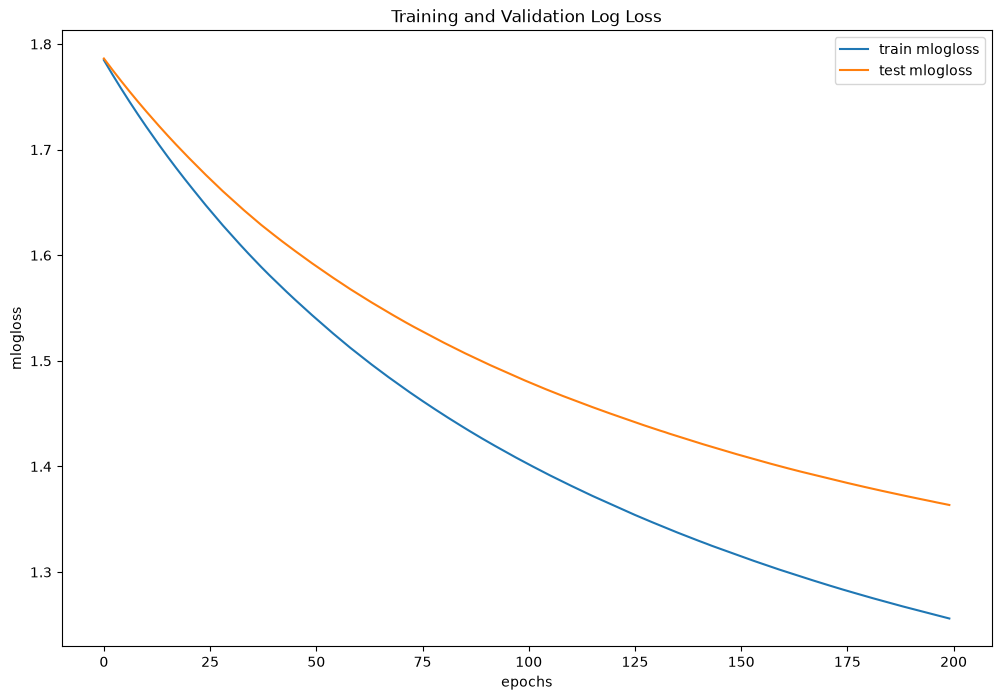

In [18]:
fig, ax = plt.subplots(figsize=(12,8))
ax.plot(evals_result['train']['mlogloss'],label='train mlogloss')
ax.plot(evals_result['test']['mlogloss'], label='test mlogloss')
ax.plot()
ax.legend()
plt.xlabel("epochs")
plt.ylabel('mlogloss')
plt.title("Training and Validation Log Loss")


## **12. Classification Performance Analysis**

In [19]:
cm = confusion_matrix(y_test, ypred_classes)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[262 187  54  14  14 189]
 [113 545 189   5   8  86]
 [  6  20  40   0   0   3]
 [ 11  11   5  89 122  67]
 [ 12  12   8  59 355  62]
 [103  82  31 182 172 492]]


In [20]:
label_encoder.classes_ = ['Highest Cost', 'Higher Cost', 'High Cost','Normal Cost', 'Low Cost','Lower Cost']

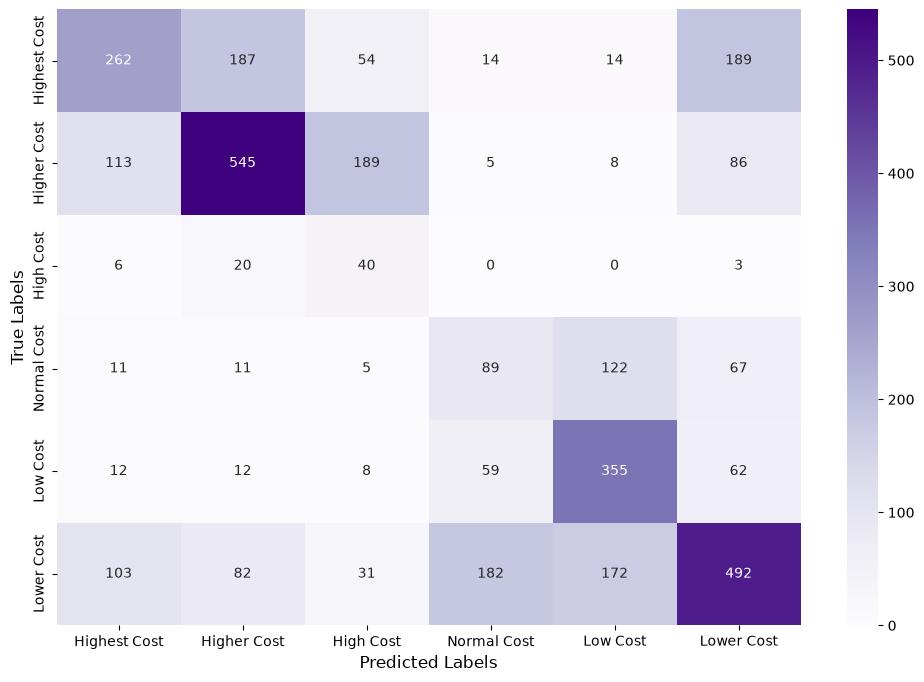

In [21]:
plt.figure(figsize=(12,8))
sns.heatmap(cm,annot=True,fmt='.0f',xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_,cmap='Purples')
plt.xlabel('Predicted Labels', fontsize=12)
plt.ylabel('True Labels', fontsize=12)
plt.show()

## **13. Cross-Validation Strategy**

In [22]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

## **14. Cross-Validation Results**

In [23]:
cv_scores = []



for train_idx, val_idx in cv.split(X_train, y_train):
    X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_va = y_train[train_idx], y_train[val_idx]
    sample_weights = compute_sample_weight(class_weight='balanced',y=y_tr)

    d_tr = xgb.DMatrix(X_tr, label=y_tr, weight=sample_weights)
    d_va = xgb.DMatrix(X_va, label=y_va)
    
    evals = [(d_tr, 'train'), (d_va, 'val')]
    model = xgb.train(param, d_tr, num_round, evals=evals, verbose_eval=False)
    
    preds = model.predict(d_va)
    pred_classes = np.argmax(preds, axis=1)
    acc = np.mean(pred_classes == y_va)
    cv_scores.append(acc)
    ypred_prob = model.predict(d_va)

    ypred_prob_cl = np.argmax(ypred_prob, axis=1)
    
accuracy = accuracy_score(y_va, ypred_prob_cl)
print(classification_report(y_va, ypred_prob_cl))
print(f"Cross-Validation Accuracy Scores: {cv_scores}")
print(f"Mean CV Accuracy: {np.mean(cv_scores):.4f} (+/- {np.std(cv_scores):.4f})")

              precision    recall  f1-score   support

           0       0.44      0.35      0.39       479
           1       0.62      0.50      0.55       632
           2       0.12      0.67      0.20        46
           3       0.20      0.21      0.21       203
           4       0.52      0.68      0.59       339
           5       0.54      0.45      0.49       707

    accuracy                           0.46      2406
   macro avg       0.41      0.48      0.41      2406
weighted avg       0.50      0.46      0.47      2406

Cross-Validation Accuracy Scores: [np.float64(0.49314499376817617), np.float64(0.49231408392189446), np.float64(0.4786040714582468), np.float64(0.4860822600747819), np.float64(0.5066500415627597), np.float64(0.4613466334164589)]
Mean CV Accuracy: 0.4864 (+/- 0.0140)


## **15. Baseline Performance Summary**

In [24]:

summary_data = {
    "Metric": ["Test Accuracy", "Mean CV Accuracy", "Train Logloss", "Test Logloss"],
    "Score": [
        accuracy, 
        np.mean(cv_scores), 
        bst.eval(dtrain).split()[-1], 
        bst.eval(dtest).split()[-1]
    ]
}

performance_summary_df = pd.DataFrame(summary_data)
display(performance_summary_df)

,Metric,Score
0,Test Accuracy,0.461347
1,Mean CV Accuracy,0.486357
2,Train Logloss,eval-mlogloss:1.25604182294846667
3,Test Logloss,eval-mlogloss:1.36352538331889050


## **16. Model Artifact Saving**

In [30]:
from pathlib import Path
model_save = MODELS_DIR / 'baseline-model.json'
bst.save_model(model_save)

## **17. Experiment Conclusions**